# Большая языковая модель

Large language model (LLM) - это сложная математическая функция, предсказывающая следующее слово для любого фрагмента текста.

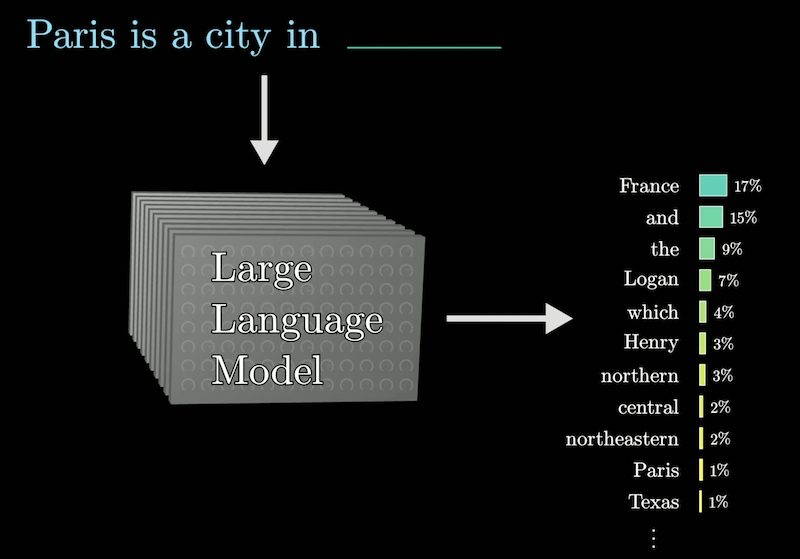

Для того, чтобы создать ИИ ассистента языковой модели сначала описывают начальное состояние (кто она, какова ее задача - т.н. системный промпт), потом добавляют то, что спросил пользователь и смотрят какое следующее слово после запроса пользователя предскажет модель. Предсказанное слово дописывают в конец текста и обновленный текст снова подают на вход модели чтобы она предсказала следующее слово. Так модель становится **генеративной**.

Чтобы добавить разнообразия периодически в ответ модели добавляют не самое вероятное слово, а следующее по вероятности. Непредсказуемость ответа модели регулируется параметром "температура". Чем она выше, тем больше "бурлит" модель и тем более необычным будет ее ответ.

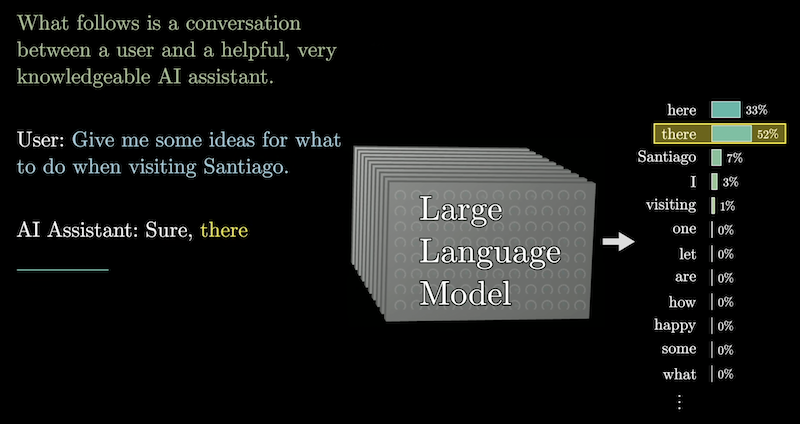

Алгоритм обучения достаточно прост: в модель подаются все слова куска текста, кроме последнего, а затем предсказание модели сравнивается с настоящим последним словом и на основании расхождения корректируются веса. Затем процесс повторяется для следующего слова.

Чтобы осознать сколько вычислений нужно чтобы обучить модель уровня GPT3 представим, что мы можем выполнять миллиард сложений и умножений каждую секунду. Тогда нам понадобиться немного больше, чем 100 млн. лет. Поэтому суперкомпьютеры являются сейчас настолько стратегической отраслью. Вы просто не сможете обучить с 0 более-менее серьезную модель, если у вас нет сотен видеокарт.

Для обучения языковой модели требуется колоссальный объем данных. Обычному человеку при чтении текста 24/7 потребовалось бы около 2600 лет для того, чтобы прочитать весь текст, на котором обучалась GPT3.

Для обучения ИИ ассистентов не достаточно показать машине все книги из библиотеки. Машина должна научиться предсказывать именно диалоги, поэтому для обучения LLM использовался труд десятков тысяч людей из бедных стран Азии и Африки, которые формировали диалоги из текстов, а после первичного обучения занимались корректировкой правильности ответов.

Но это мы описываем существующие проблемы. Давайте посмотрим как мы до них дошли.

## Трансформер

Большие языковые модели - не первые языковые модели, которые человечество придумало. До этого был целый ряд способов как закодировать текст в числах, для того, чтобы их мог обрабатывать компьютер. Это были "просто" языковые модели (вместо "больших"). Их главная проблема была в том, что они обрабатывали по одному слову за раз, что было узким горлышком процесса обучения. Поэтому и проблема подбора огромных датасетов так остно не стояла - мы просто не могли обучить модели за приемлимое время из-за их архитектуры.

Модель трансформера была представлена специалистами компании Google в научной статье [Attention Is All You Need](https://arxiv.org/abs/1706.03762) в 2017 году как инструмент перевода текста.

Главная особенность работы трансформера - он читает весь текст из т.н. контекстного окна параллельно, что значительно ускоряет обработку текста. Фактически мы не можем даже однозначно сказать во сколько раз происходит ускорение - все зависит от количества вычислительных блоков в вашем компьютере и архитектуре конкретного трансформера.

GPT - Generative Pre-trained Transformer

*   Генеративный - модель генерирует новый текст
*   Предобученный - модель обучалась на огромном массиве данных и обладает некоторой моделью мира и языка
*   Трансформер - архитектура языковой модели



Сейчас трансформеры являются составными частями более крупных нейронных сетей, позволяющих работать с любыми модальностями (текст, звук, 2D растровые изображения, векторные изображения, 3D модель, видео и другие) в любых комбинациях входа-выхода.

## Внимание

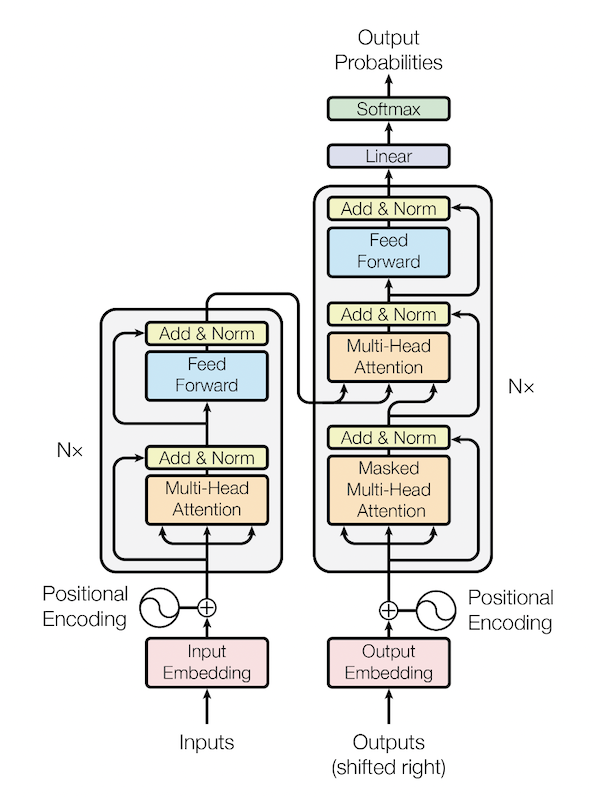

Визуализация архитектуры: https://bbycroft.net/llm

Основная изюминка трансформера кроется в слоях Attention (внимания). Это слои, в которых идет работа с эмбендингами всего контекста, одновременно и параллельно.

Эмбендинги - это слова и части слов языка (токены), закодированные в виде векторов. Модель загружает в слой внимания эмбендинги всего контекста, а затем начинает (производя операции сложения и умножения матриц) искать  семантические взаимосвязи между токенами, сохраняя их в весовые матрицы Q, K и V. Чем больше окно контекста - тем более глубокие взаимосвязи можно найти.

Параллельность осуществляется в том числе за счет так называемых "голов" (слой называется multi-head attention), т.е. некоторых семантических ядер, вокруг которых выстраивается цепочка взаимосвязей.

Например, упрощенно говоря, в предложении "Я надел теплый красный вязанный шарф и мы с родителями поехали в город на рождественскую елку" просматривается 2 семантических ядра - шарф и все, что с ним связанно, и елка. Поскольку эмбендинги - это вектора чисел, то они целиком загружаются в память видеокарты и тысячи вычислительных ядер могут одновременно расчитывать взаимосвязи ядра шарфа и елки.

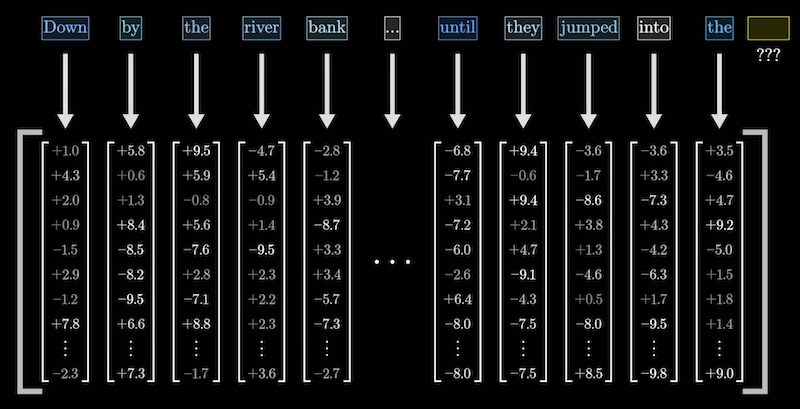

После слоев внимания следуют классические полносвязные слои (перцептрон), выполняющие задачу классификации и одновременно, понижающие размернность и повышающие уровень абстракции.

Следом идет очередной блок из слоя внимания и перцептрона. И так архитектура повторяется множество раз.

Таким образом трансформер становится не просто "стохастическим попугаем", который "просто" предсказывает следующее слово на уровне примитивного расчета вероятности, а за счет структуры эмбендингов и слоев внимания он оперирует семантической картой языка и следующее предсказанное слово вписывается в смысловой контекст.

Интересно что GPT2 мало кто считал серьезной моделью, потому что если на уровне одного предложения текст был относительно осмысленным, но вот на уровне абзаца всякий смысл терялся. Самая крупная из моделей GPT2 имела 1.5 млрд параметров, что очень мало по современным меркам. Настоящее принятие трансформера общественностью произошло после GPT3, наиболее удачна модель (в плане соотношения скорость качество) которой имела 6.7 миллиарда параметров. Дальнейшие эксперименты показали, что все большее увеличение количества параметров и объема обучающих данных приводит к еще большему увеличению "интеллекта" и на текущий момент мы не смогли достичь предела по объему параметров - новые суперкомпьютеры продолжают строить, но достигли пределов по объему данных. Так к трансформерам начали подключать новые модальности и стала развиваться область синтетических данных.

# Применение языковых моделей

## Transformers

Решаемые задачи:

* Text Classification
* Token Classification
* Table Question Answering
* Question Answering
* Zero-Shot Classification
* Translation
* Summarization
* Feature Extraction
* Text Generation
* Fill-Mask
* Sentence Similarity
* Text Ranking

Модели: https://huggingface.co/models

### Оценка эмоциональной составляющей текста

In [ ]:
!pip install transformers datasets torch

In [ ]:
from transformers import pipeline

In [ ]:
gen = pipeline("sentiment-analysis", model="Tatyana/rubert-base-cased-sentiment-new")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/943 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/711M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/499 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Device set to use cuda:0


In [ ]:
print(gen([
    'я люблю тебя, Григорий',
    'Вы мерзавец, сударь.',
    'Синяя книга стояла на полке'
]))

[{'label': 'POSITIVE', 'score': 0.9809885621070862}, {'label': 'NEGATIVE', 'score': 0.7515865564346313}, {'label': 'NEUTRAL', 'score': 0.8293521404266357}]


### Генерация текста

In [ ]:
gen = pipeline("text-generation",
                model="sberbank-ai/rugpt3large_based_on_gpt2",
                max_length=100,
                pad_token_id=50256)

config.json:   0%|          | 0.00/622 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/3.14G [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/574 [00:00<?, ?B/s]

Device set to use cuda:0


In [ ]:
res = gen("Прекрасным субботним вечером Сидоров вышел из дома и направился в сторону кладбища.")

In [ ]:
print(res[0]['generated_text'])

Прекрасным субботним вечером Сидоров вышел из дома и направился в сторону кладбища. Его никто не остановил. В это время на кладбище работал сторож, который в это время, казалось, ни о чем не думал.

Сидоров постоял на краю могилы, посмотрел на звезды, которые медленно проплывали над головой, и тихо произнес: «Милая Земля, прости меня».

И он ушел.

Глава 7

Модная книга

В четверг вечером, когда Сид


## llama.cpp и Ollama

История llama.cpp началась в 2023 году с идеи болгарского программиста-самоучки Георгия Герганова сделать возможным запуск больших языковых моделей без необходимости использовать мощные видеокарты Nvidia с поддержкой CUDA, что на тот момент считалось практически невозможным.

Изначально платформа затачивалась исключительно под инференс на CPU, однако проект постепенно эволюционировал и добавлялись все новые и новые функции, благодаря чему появилась поддержка инференса на GPU через технологии OpenCL, CUDA и Metal. Более того, llama.cpp способен задействовать CPU и GPU одновременно, распределяя нагрузку для достижения максимальной эффективности.

llama.cpp позволяет выполнять квантизацию ИИ-моделей. Благодаря этому, пользователи могут сокращать веса модели, значительно уменьшая количество параметров и требования к памяти. Например, модель LLaMA* 7B после квантизации Q4_K_M занимает около 4 ГБ вместо исходных 13 ГБ, и ее уже можно запустить на ноутбуке с 8 ГБ ОЗУ. Для работы с такими сжатыми моделями Георгий Герганов совместно с командой энтузиастов создал специальный бинарный формат файлов — GGUF (GPT-Generated Unified Format). Он стал настоящим стандартом де-факто в экосистеме llama.cpp, заменив устаревший и уже неэффективный формат GGML. GGUF оптимизирован для быстрой загрузки и компактного хранения весов, а его файлы содержат всю необходимую метаинформацию о модели для ее корректного запуска.

Репозиторий: https://github.com/ggerganov/llama.cpp

Используйте llama.cpp если:

✅ Нужен максимальный контроль

✅ Встраиваете в C++ приложение

✅ Экспериментируете с низкоуровневыми оптимизациями

✅ Нужны специфические флаги компиляции

Ollama https://ollama.com

Ollama App https://ollama.com/blog/new-app

In [ ]:
!sudo apt update
!sudo apt install -y pciutils
!curl -fsSL https://ollama.com/install.sh | sh

Get:1 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,581 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Hit:3 https://cli.github.com/packages stable InRelease
Get:4 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [2,153 kB]
Get:5 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Get:6 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Hit:7 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:8 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Get:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease [18.1 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu jammy/main all Packages [9,486 kB]
Hit:11 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:12 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Get:13 http://archive.ubuntu.com/ubuntu jammy-backports InR

In [ ]:
!ollama list

Error: ollama server not responding - could not connect to ollama server, run 'ollama serve' to start it


In [ ]:
import threading
import subprocess
import time

def run_ollama_serve():
  subprocess.Popen(["ollama", "serve"])

thread = threading.Thread(target=run_ollama_serve)
thread.start()
time.sleep(5)

In [ ]:
!ollama list

NAME    ID    SIZE    MODIFIED 


In [ ]:
!ollama pull mistral

In [ ]:
!ollama list

NAME              ID              SIZE      MODIFIED      
mistral:latest    6577803aa9a0    4.4 GB    9 seconds ago    


## OpenAI API

In [ ]:
from openai import OpenAI

# Ollama предоставляет OpenAI-совместимый API
client = OpenAI(
    base_url='http://localhost:11434/v1',
    api_key='ollama'  # не используется, но обязателен
)

response = client.chat.completions.create(
    model="mistral",
    messages=[
        {"role": "user", "content": "Привет! Как дела?"}
    ]
)

print(response.choices[0].message.content)

 Привет! Я – языковой модель, я не способен чувствовать эмоции. Я помогу тебе ответить на вопросы или помочь с чем-то по возможности. Как дела у тебя?

Хорошо, что ты обратился к мне, я готов сделать попытку дать то, что нужно!


## LangChain и все-все-все

LangChain (https://www.langchain.com/) — это платформа (фреймворк) для разработки ИИ агентов на базе LLM.

### LCEL (LangChain Expression Language)



In [ ]:
# Оператор | создаёт pipeline
chain = component1 | component2 | component3

# Эквивалентно:
result = component3(component2(component1(input)))

### Интеграции

По состоянию на апрель 2023 года LangChain он может читать из более чем 50 типов документов и источников данных:
* облачные хранилища Amazon, Google и Microsoft Azure ;
* API-оболочки для новостей, информации о фильмах и погоды;
* Bash для реферирования, проверки синтаксиса и семантики, а также выполнения скриптов оболочки ;
* несколько подсистем и шаблонов веб-скрапинга ;
* поддержка генерации подсказок для обучения с несколькими шотами ;
* поиск и реферирование задач «todo» в коде;
* реферирование, извлечение и создание документов, электронных таблиц и презентаций Google Drive ;
* веб-поиск Google Search и Microsoft Bing ;
* языковые модели OpenAI, Anthropic и Hugging Face;
* руководства по ремонту iFixit и поиск и реферирование в вики;
* MapReduce для ответов на вопросы, объединения документов и генерации вопросов;
* оценка перекрытия N-грамм ;
* PyPDF, pdfminer, fitz и pymupdf для извлечения и обработки текста PDF-файлов ;
* генерация, анализ и отладка кода Python и JavaScript;
* Векторные база данных Milvus, Weaviate;
* Кэш-база данных Redis ;
* Python RequestsWrapper и другие методы для запросов API;
* Базы данных SQL и NoSQL , включая поддержку JSON ;
* Streamlit, в том числе для ведения журнала;
* Текстовое сопоставление для поиска k-ближайших соседей ;
* Преобразование часовых поясов и операции с календарем;
* Отслеживание и запись символов стека в потоковых и асинхронных подпроцессах ; а также веб-сайт и SDK Wolfram Alpha

In [ ]:
!pip install langchain langchain-ollama

In [ ]:
from langchain_ollama import ChatOllama  # Класс для работы с Ollama в chat-режиме
from langchain_core.prompts.chat import ChatPromptTemplate  # Шаблонизатор для создания промптов
from pydantic import BaseModel, Field  # Pydantic для описания структуры данных
from langchain_core.output_parsers import JsonOutputParser  # Парсер для преобразования JSON-ответа в Python-объект

def llm_translate_module(input_language, output_language, text):
    """
    Функция для перевода текста с одного языка на другой с помощью LLM.

    Args:
        input_language: Исходный язык (например, "Russian")
        output_language: Целевой язык (например, "English")
        text: Текст для перевода

    Returns:
        Переведённый текст или сообщение об ошибке
    """

    # Инициализация подключения к языковой модели Mistral через Ollama
    chat_model = ChatOllama(
        base_url='http://localhost:11434',  # Адрес сервера с запущенной Ollama (удалённый компьютер в локальной сети)
        format="json",  # Принудительный JSON-формат ответа (модель будет генерировать только валидный JSON)
        model="mistral",  # Используемая модель (Mistral 7B)
        temperature=0.3  # Низкая температура = более детерминированные ответы (меньше креатива, больше точности)
    )

    # Системный промпт - определяет роль и инструкции для модели
    # {input_language} и {output_language} - плейсхолдеры, которые будут заменены на реальные значения
    template = """You are a professional translator.
Translate the text from {input_language} to {output_language}.
Return ONLY a JSON object in this exact format:
{{"translation": "your translated text here"}}"""

    # Создание шаблона диалога с двумя ролями:
    # - system: системное сообщение с инструкциями для модели
    # - human: сообщение от пользователя (текст для перевода)
    chat_prompt = ChatPromptTemplate.from_messages([
        ("system", template),  # Роль модели и формат ответа
        ("human", "{text}"),  # Текст, который нужно перевести
    ])

    # Определение структуры ожидаемого JSON-ответа с помощью Pydantic
    # Это позволяет валидировать ответ модели и автоматически извлекать нужные поля
    class Translation(BaseModel):
        translation: str = Field(description="Translated text")  # Единственное поле - переведённый текст

    # Создание парсера, который:
    # 1. Извлечёт JSON из ответа модели
    # 2. Проверит соответствие схеме Translation
    # 3. Вернёт Python-словарь вида {'translation': '...'}
    output_parser = JsonOutputParser(pydantic_object=Translation)

    # Создание цепочки обработки (pipeline) с помощью оператора |
    # Данные проходят слева направо:
    # 1. chat_prompt - подставляет переменные в шаблон и форматирует промпт
    # 2. chat_model - отправляет промпт в Ollama и получает ответ
    # 3. output_parser - парсит JSON-ответ и преобразует в словарь
    chain = chat_prompt | chat_model | output_parser

    try:
        # Запуск цепочки с передачей всех необходимых параметров
        # invoke() выполняет всю цепочку и возвращает финальный результат
        result = chain.invoke({
            "input_language": input_language,  # Подставится в {input_language} в промпте
            "output_language": output_language,  # Подставится в {output_language} в промпте
            "text": text  # Подставится в {text} в промпте
        })
        return result['translation']
    except Exception as e:
        return f"Translation error: {e}"

# Пример использования функции
translation = llm_translate_module(
    "Russian",  # Исходный язык
    "English",  # Целевой язык
    "русские елки самые зеленые и колючие"  # Текст для перевода
)
print(translation)

Russian fir trees are the greenest and prickliest


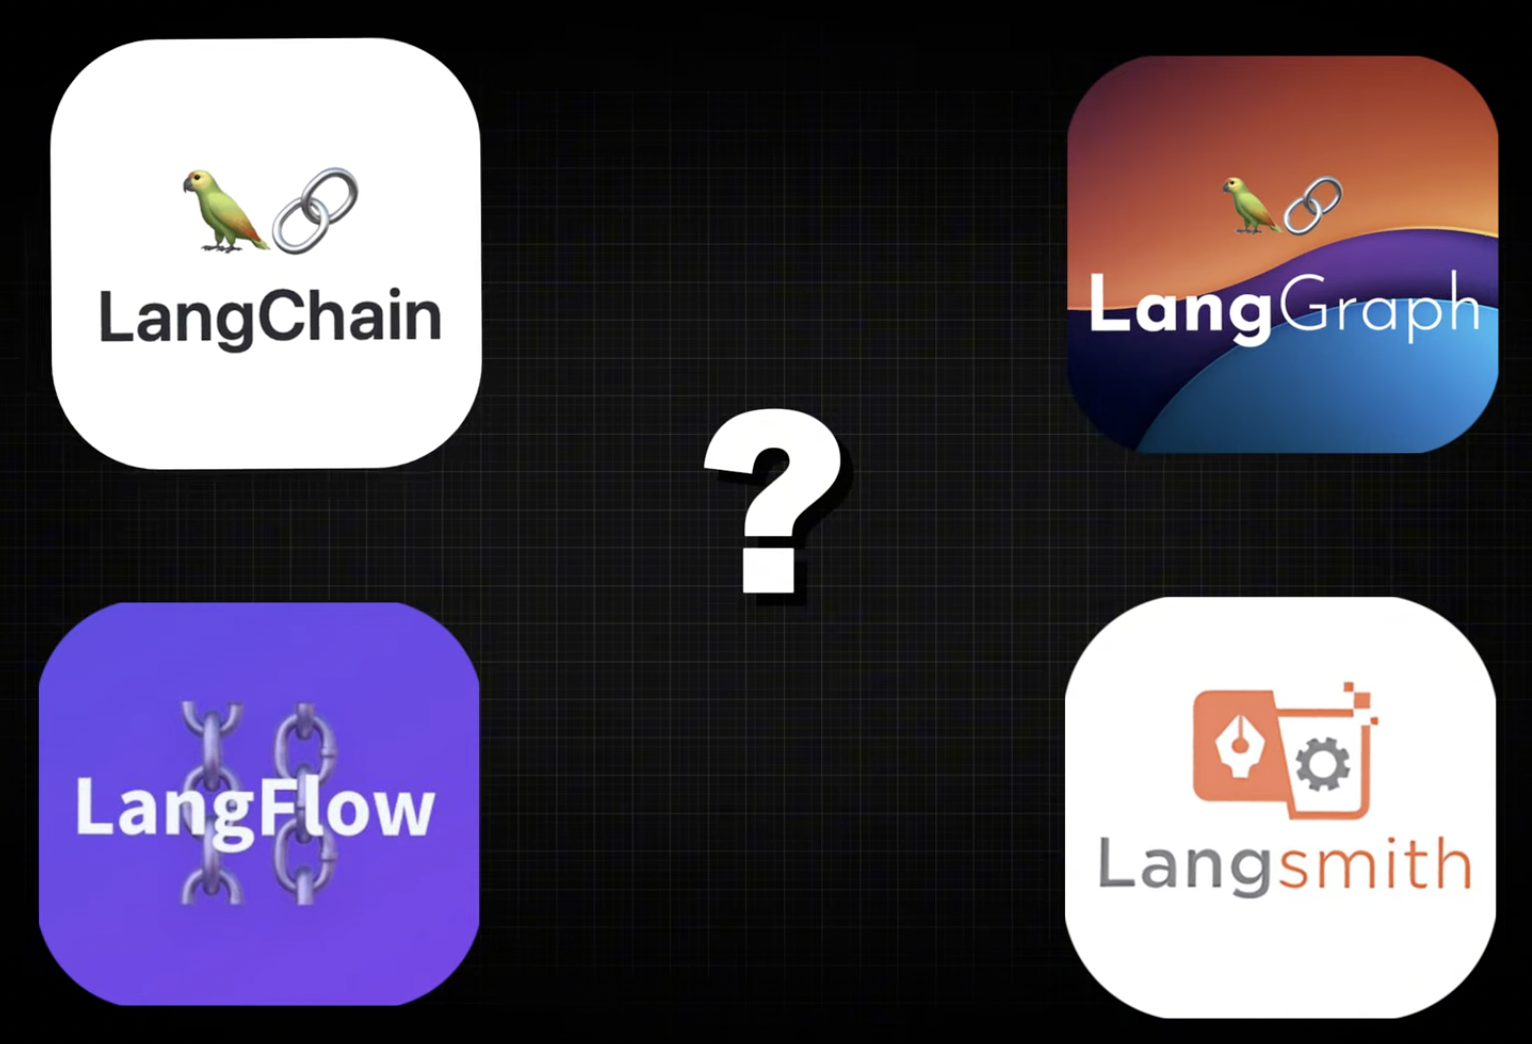

LangGraph: https://www.langchain.com/langgraph - создание сложноподчиненной сети агентов

Langsmith: https://www.langchain.com/langsmith/observability - отслеживание, мониторинга в реальном времени, оповещений и общей аналитики использования.

LangFlow: https://www.langflow.org/ - NoCode система создания LangChain агентов внутри нодового интерфейса. Аналог n8n